In [1]:
import pandas as pd

In [2]:
print("Pandas imported successfully")

Pandas imported successfully


In [3]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


## Project Assumptions

1. Each row represents one customer.
2. Churn column is the target variable.
3. Customer details are used as input features.
4. The dataset contains more non-churn customers than churn customers.
5. The dataset is split into 80% training and 20% testing.
6. The test data will not be used during training or model selection.

## Evaluation Metric

We will optimise F1-score because the dataset is imbalanced.

F1-score balances precision and recall.

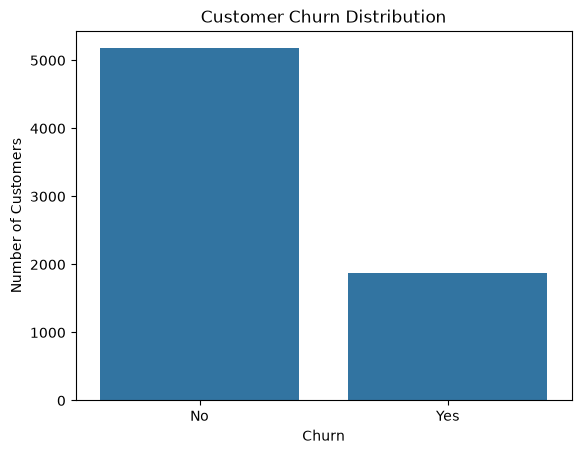

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

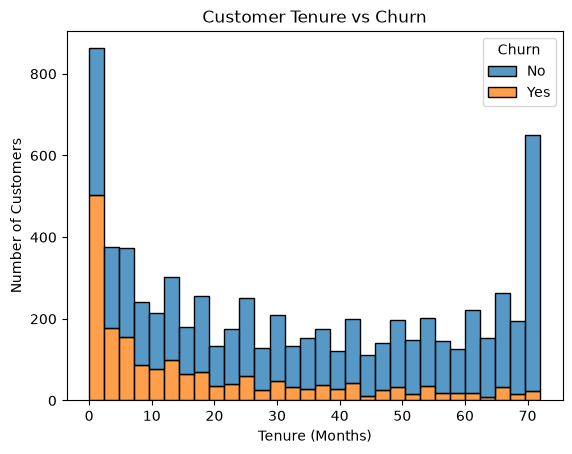

In [15]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

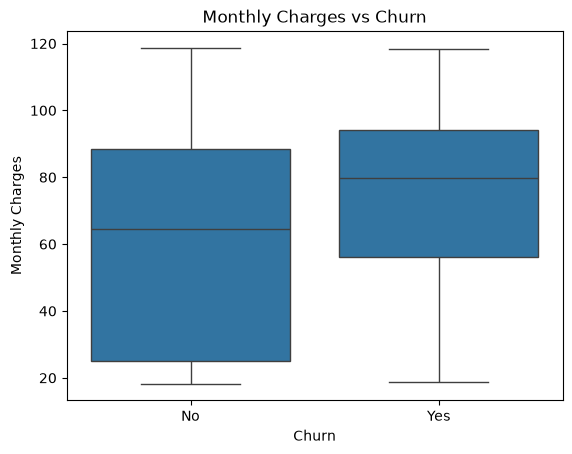

In [16]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

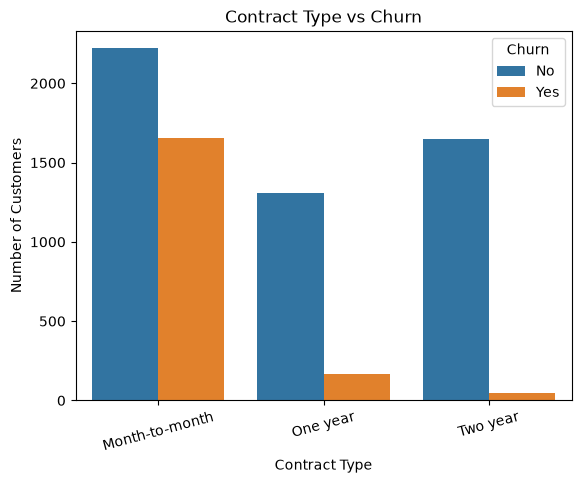

In [17]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

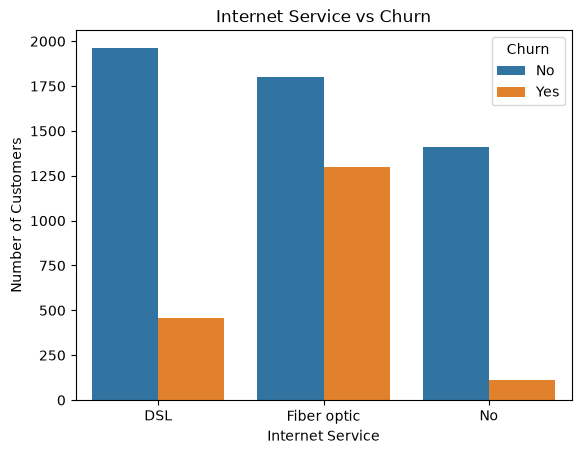

In [18]:
sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

## EDA Findings

1. The dataset contains more non-churn customers than churn customers.
2. Customers with shorter tenure show higher churn.
3. Monthly charges may influence customer churn.
4. Month-to-month contract customers show higher churn.
5. Fiber optic internet customers show noticeable churn.

## Conclusion

Customer tenure, monthly charges, contract type, and internet service are important factors to investigate for customer churn prediction.

In [19]:
X_train = X_train.drop("customerID", axis=1)
X_test = X_test.drop("customerID", axis=1)

print(X_train.shape)

(5634, 19)


In [20]:
print(X_train.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64


In [21]:
print(X_train.dtypes)

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
dtype: object


In [22]:
X_train["TotalCharges"] = pd.to_numeric(
    X_train["TotalCharges"], errors="coerce"
)

In [23]:
print(X_train["TotalCharges"].isnull().sum())

8


In [24]:
median_value = X_train["TotalCharges"].median()

X_train["TotalCharges"] = X_train["TotalCharges"].fillna(median_value)

X_test["TotalCharges"] = pd.to_numeric(
    X_test["TotalCharges"], errors="coerce"
)

X_test["TotalCharges"] = X_test["TotalCharges"].fillna(median_value)

print(X_train["TotalCharges"].isnull().sum())

0


In [25]:
categorical_cols = X_train.select_dtypes(include=["object", "str"]).columns.tolist()

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [26]:
from sklearn.preprocessing import OneHotEncoder

In [27]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [28]:
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])

X_test_encoded = encoder.transform(X_test[categorical_cols])

print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)

Training encoded shape: (5634, 41)
Testing encoded shape: (1409, 41)


In [29]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print(numerical_cols)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [30]:
from sklearn.preprocessing import StandardScaler

In [31]:
scaler = StandardScaler()

In [32]:
X_train_scaled = scaler.fit_transform(X_train[numerical_cols])

X_test_scaled = scaler.transform(X_test[numerical_cols])

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (5634, 4)
Testing scaled shape: (1409, 4)


In [33]:
X_train_processed = np.hstack((X_train_encoded, X_train_scaled))

X_test_processed = np.hstack((X_test_encoded, X_test_scaled))

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

NameError: name 'np' is not defined

In [34]:
import numpy as np

In [35]:
X_train_processed = np.hstack((X_train_encoded, X_train_scaled))

X_test_processed = np.hstack((X_test_encoded, X_test_scaled))

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

Training data: (5634, 45)
Testing data: (1409, 45)


In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [38]:
model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [39]:
y_pred = model.predict(X_test_processed)

print(y_pred[:10])

['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.8055358410220014


In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



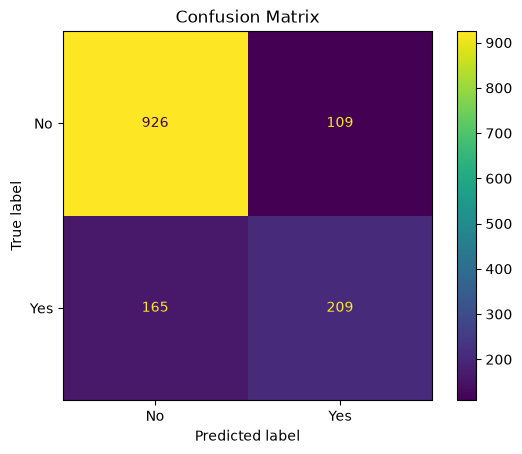

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot()
plt.title("Confusion Matrix")
plt.show()

In [43]:
print("Model: Logistic Regression")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(
    __import__("sklearn.metrics", fromlist=["f1_score"]).f1_score(
        y_test, y_pred, pos_label="Yes"
    ), 2
))

Model: Logistic Regression
Accuracy: 80.55 %
F1 Score: 0.6


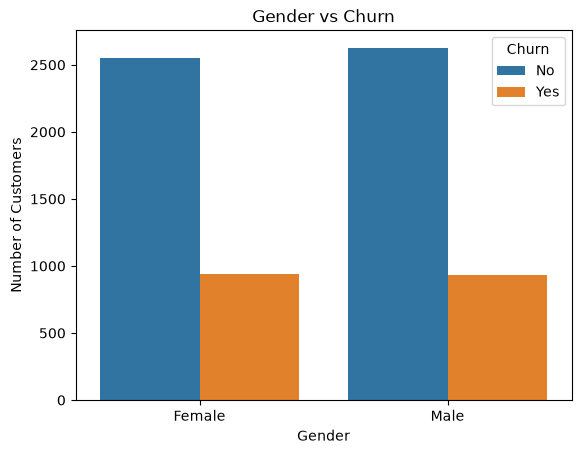

In [44]:
sns.countplot(data=df, x="gender", hue="Churn")

plt.title("Gender vs Churn")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

In [45]:
from sklearn.ensemble import RandomForestClassifier

In [46]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

In [47]:
rf_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [48]:
rf_pred = rf_model.predict(X_test_processed)

print(rf_pred[:10])

['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


In [49]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 76.79 %


In [50]:
from sklearn.metrics import f1_score

rf_f1 = f1_score(y_test, rf_pred, pos_label="Yes")

print("Random Forest F1 Score:", round(rf_f1, 2))

Random Forest F1 Score: 0.59


In [51]:
from sklearn.metrics import f1_score

lr_f1 = f1_score(y_test, y_pred, pos_label="Yes")

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "F1 Score": [lr_f1, rf_f1]
})

print(comparison)

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.805536  0.604046
1        Random Forest  0.767921  0.592777


## Model Comparison & Conclusion

Two machine learning models were trained:

1. Logistic Regression
2. Random Forest

### Results

- Logistic Regression Accuracy: 80.55%
- Logistic Regression F1-score: 0.604
- Random Forest Accuracy: 76.79%
- Random Forest F1-score: 0.593

### Conclusion

Logistic Regression performed better than Random Forest based on F1-score.

Therefore, Logistic Regression is selected as the preferred model for this customer churn prediction project.

In [52]:
print("Final Model: Logistic Regression")
print(classification_report(y_test, y_pred))

Final Model: Logistic Regression
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [ ]:
# Customer Churn Prediction

## Project Overview

This project predicts whether a telecom customer is likely to leave the company (Churn) using Machine Learning.

The goal is to identify customers who may leave and help the company improve customer retention.

## Dataset

- Dataset: Telco Customer Churn
- Total Records: 7043
- Total Columns: 21
- Target Column: Churn
- Target Values: Yes / No

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Project Workflow

1. Data Loading
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Train-Test Split
5. Data Preprocessing
6. Model Training
7. Model Evaluation
8. Model Comparison

## Model Performance

Two Machine Learning models were trained and compared.

| Model | Accuracy | F1 Score |
|---|---:|---:|
| Logistic Regression | 80.55% | 0.60 |
| Random Forest | 76.79% | 0.59 |

### Final Model

Logistic Regression was selected because it achieved better accuracy and F1 score.

## Project Structure

Customer_Churn_Prediction/
│
├── data/
│   └── WA_Fn-UseC_-Telco-Customer-Churn.csv
│
├── churn_eda.ipynb
│
└── README.md
